In [1]:
from pathlib import Path

# Find the folder where our Jupyter Notebook is saved
project_path = Path.cwd()

print("Current project folder:")
print(project_path)

# Search for the nuclear power plant dataset
dataset_folders = list(project_path.rglob("Malfunctions"))

print("\nDataset folders found:", len(dataset_folders))

for folder in dataset_folders:
    print(folder)

Current project folder:
C:\Users\acer\Downloads\ML Final Course Project (Ameer,Zaid,Ahmed)

Dataset folders found: 1
C:\Users\acer\Downloads\ML Final Course Project (Ameer,Zaid,Ahmed)\NPPmalfunctions-main\NPPmalfunctions-main\Malfunctions


In [2]:

# Select the dataset folder we found
dataset_path = dataset_folders[0]

# Find all Excel files (.xlsx and .xls)
excel_files = sorted(
    list(dataset_path.rglob("*.xlsx")) +
    list(dataset_path.rglob("*.xls"))
)

print("Total Excel files found:", len(excel_files))

print("\nFirst 10 Excel files:")
for file in excel_files[:10]:
    print(file.relative_to(dataset_path))


Total Excel files found: 42

First 10 Excel files:
00 - Normal Operation\0.xls
00 - Normal Operation\0.xlsx
01 - Loss of Coolant Accident (Hot Leg)\1.xls
01 - Loss of Coolant Accident (Hot Leg)\1.xlsx
02 - Loss of Coolant Accident (Cold Leg)\2.xls
02 - Loss of Coolant Accident (Cold Leg)\2.xlsx
03 - Steam Line Break Inside Containment\3.xls
03 - Steam Line Break Inside Containment\3.xlsx
04 - Steam Line Break Outside Containment\4.xls
04 - Steam Line Break Outside Containment\4.xlsx


In [3]:

import pandas as pd

# Select the Normal Operation Excel file
normal_file = dataset_path / "00 - Normal Operation" / "0.xlsx"

# Load the dataset
normal_df = pd.read_excel(normal_file)

# Display basic dataset information
print("Dataset shape:", normal_df.shape)
print("Number of rows:", normal_df.shape[0])
print("Number of columns:", normal_df.shape[1])

print("\nFirst 5 rows:")
display(normal_df.head())

print("\nColumn names:")
print(normal_df.columns.tolist())


Dataset shape: (609, 97)
Number of rows: 609
Number of columns: 97

First 5 rows:


,TIME,P,TAVG,THA,THB,TCA,TCB,WRCA,WRCB,PSGA,...,MDBR,MCRT,MGAS,TCRT,TSLP,PPM,RRCA,RRCB,RRCO,WFLB
0,0,155.500015,310.000000,327.823975,327.823212,292.176056,292.176788,16515.818359,33031.636719,67.000031,...,0,0,0,50,50,200,1,1,1.0,0
1,1,155.494339,309.993713,327.823273,327.822479,292.175049,292.175842,16515.818359,33031.636719,66.999924,...,0,0,0,50,50,200,1,1,1.0,0
2,2,155.486084,309.987915,327.821381,327.820618,292.173492,292.174286,16515.818359,33031.636719,66.999176,...,0,0,0,50,50,200,1,1,1.0,0
3,3,155.478165,309.982910,327.818756,327.817932,292.171509,292.172272,16515.818359,33031.636719,66.997894,...,0,0,0,50,50,200,1,1,1.0,0
4,4,155.471954,309.979370,327.815796,327.814972,292.169220,292.170013,16515.818359,33031.636719,66.996246,...,0,0,0,50,50,200,1,1,1.0,0



Column names:
['TIME', 'P', 'TAVG', 'THA', 'THB', 'TCA', 'TCB', 'WRCA', 'WRCB', 'PSGA', 'PSGB', 'WFWA', 'WFWB', 'WSTA', 'WSTB', 'VOL', 'LVPZ', 'VOID', 'WLR', 'WUP', 'HUP', 'HLW', 'WHPI', 'WECS', 'QMWT', 'LSGA', 'LSGB', 'QMGA', 'QMGB', 'NSGA', 'NSGB', 'TBLD', 'WTRA', 'WTRB', 'TSAT', 'QRHR', 'LVCR', 'SCMA', 'SCMB', 'FRCL', 'PRB', 'PRBA', 'TRB', 'LWRB', 'DNBR', 'QFCL', 'WBK', 'WSPY', 'WCSP', 'HTR', 'MH2', 'CNH2', 'RHBR', 'RHMT', 'RHFL', 'RHRD', 'RH', 'PWNT', 'PWR', 'TFSB', 'TFPK', 'TF', 'TPCT', 'WCFT', 'WLPI', 'WCHG', 'RM1', 'RM2', 'RM3', 'RM4', 'RC87', 'RC131', 'STRB', 'STSG', 'STTB', 'RBLK', 'SGLK', 'DTHY', 'DWB', 'WRLA', 'WRLB', 'WLD', 'MBK', 'EBK', 'TKLV', 'FRZR', 'TDBR', 'MDBR', 'MCRT', 'MGAS', 'TCRT', 'TSLP', 'PPM', 'RRCA', 'RRCB', 'RRCO', 'WFLB']


In [4]:

# Check the quality of our Normal Operation dataset

print("Dataset shape:", normal_df.shape)

print("\nMissing values:", normal_df.isnull().sum().sum())

print("Duplicate rows:", normal_df.duplicated().sum())

print("\nData types:")
print(normal_df.dtypes.value_counts())

print("\nTime range:")
print("Start:", normal_df["TIME"].min())
print("End:", normal_df["TIME"].max())

print("\nConstant columns:")
constant_columns = normal_df.columns[
    normal_df.nunique(dropna=False) <= 1
].tolist()

print(constant_columns)
print("Number of constant columns:", len(constant_columns))


Dataset shape: (609, 97)

Missing values: 0
Duplicate rows: 0

Data types:
float64    59
int64      38
Name: count, dtype: int64

Time range:
Start: 0
End: 608

Constant columns:
['WRCA', 'WRCB', 'WLR', 'WUP', 'WHPI', 'TBLD', 'WTRA', 'WTRB', 'QRHR', 'LVCR', 'FRCL', 'PRB', 'PRBA', 'TRB', 'LWRB', 'QFCL', 'WBK', 'WSPY', 'WCSP', 'MH2', 'CNH2', 'RHBR', 'RHRD', 'WCFT', 'WLPI', 'RM1', 'RM2', 'RM3', 'RM4', 'RC87', 'RC131', 'STRB', 'STSG', 'STTB', 'SGLK', 'DTHY', 'DWB', 'WRLA', 'WRLB', 'WLD', 'MBK', 'EBK', 'TKLV', 'FRZR', 'TDBR', 'MDBR', 'MCRT', 'MGAS', 'TCRT', 'TSLP', 'PPM', 'RRCA', 'RRCB', 'RRCO', 'WFLB']
Number of constant columns: 55


In [5]:

# Identify all available .xlsx files
xlsx_files = sorted(dataset_path.rglob("*.xlsx"))

print("Total XLSX files:", len(xlsx_files))

# Inspect the structure of every scenario
dataset_summary = []

for file in xlsx_files:
    df = pd.read_excel(file)

    dataset_summary.append({
        "Scenario": file.parent.name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Missing Values": df.isnull().sum().sum(),
        "Same Columns": list(df.columns) == list(normal_df.columns)
    })

# Display the summary table
summary_df = pd.DataFrame(dataset_summary)

display(summary_df)


Total XLSX files: 21


,Scenario,Rows,Columns,Missing Values,Same Columns
0,00 - Normal Operation,609,97,0,True
1,01 - Loss of Coolant Accident (Hot Leg),606,97,0,True
2,02 - Loss of Coolant Accident (Cold Leg),603,97,0,True
3,03 - Steam Line Break Inside Containment,603,97,0,True
4,04 - Steam Line Break Outside Containment,603,97,0,True
5,05 - Spark Presence for Hydrogen Burn,603,97,0,True
6,06 - Loss of AC Power,637,97,0,True
7,07 - Loss of Flow (Locked Rotor),608,97,0,True
8,08 - Anticipated Transient without Scram,603,97,0,True
9,09 - Turbine Trip,603,97,0,True


In [6]:

print(summary_df.to_string(index=False))


                                           Scenario  Rows  Columns  Missing Values  Same Columns
                              00 - Normal Operation   609       97               0          True
            01 - Loss of Coolant Accident (Hot Leg)   606       97               0          True
           02 - Loss of Coolant Accident (Cold Leg)   603       97               0          True
           03 - Steam Line Break Inside Containment   603       97               0          True
          04 - Steam Line Break Outside Containment   603       97               0          True
              05 - Spark Presence for Hydrogen Burn   603       97               0          True
                              06 - Loss of AC Power   637       97               0          True
                   07 - Loss of Flow (Locked Rotor)   608       97               0          True
           08 - Anticipated Transient without Scram   603       97               0          True
                              

In [7]:

# Combine all valid nuclear power plant scenarios

all_data = []

for file in xlsx_files:
    scenario = file.parent.name
    scenario_id = int(scenario.split(" - ")[0])

    # Skip the scenario reserved for future use
    if scenario_id == 13:
        continue

    # Load the scenario data
    df = pd.read_excel(file)

    # Add scenario information
    df["Scenario"] = scenario
    df["Scenario_ID"] = scenario_id

    # 0 = Normal Operation, 1 = Malfunction Scenario
    df["Label"] = 0 if scenario_id == 0 else 1

    all_data.append(df)

# Combine all scenarios into one DataFrame
combined_df = pd.concat(all_data, ignore_index=True)

print("Combined dataset shape:", combined_df.shape)

print("\nLabel distribution:")
print(combined_df["Label"].value_counts())

print("\nNumber of scenarios:",
      combined_df["Scenario"].nunique())

print("\nFirst 5 rows:")
display(combined_df.head())


Combined dataset shape: (12171, 100)

Label distribution:
Label
1    11562
0      609
Name: count, dtype: int64

Number of scenarios: 20

First 5 rows:


,TIME,P,TAVG,THA,THB,TCA,TCB,WRCA,WRCB,PSGA,...,TCRT,TSLP,PPM,RRCA,RRCB,RRCO,WFLB,Scenario,Scenario_ID,Label
0,0,155.500015,310.000000,327.823975,327.823212,292.176056,292.176788,16515.818359,33031.636719,67.000031,...,50,50.0,200.0,1.0,1.0,1.0,0,00 - Normal Operation,0,0
1,1,155.494339,309.993713,327.823273,327.822479,292.175049,292.175842,16515.818359,33031.636719,66.999924,...,50,50.0,200.0,1.0,1.0,1.0,0,00 - Normal Operation,0,0
2,2,155.486084,309.987915,327.821381,327.820618,292.173492,292.174286,16515.818359,33031.636719,66.999176,...,50,50.0,200.0,1.0,1.0,1.0,0,00 - Normal Operation,0,0
3,3,155.478165,309.982910,327.818756,327.817932,292.171509,292.172272,16515.818359,33031.636719,66.997894,...,50,50.0,200.0,1.0,1.0,1.0,0,00 - Normal Operation,0,0
4,4,155.471954,309.979370,327.815796,327.814972,292.169220,292.170013,16515.818359,33031.636719,66.996246,...,50,50.0,200.0,1.0,1.0,1.0,0,00 - Normal Operation,0,0


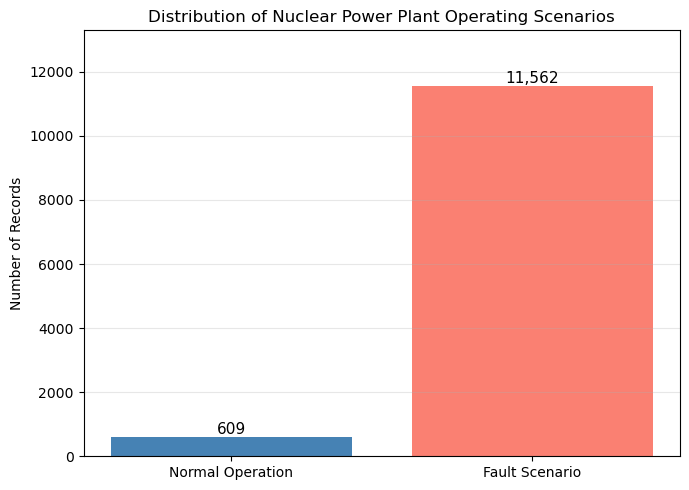

In [8]:

import matplotlib.pyplot as plt

# Count normal and fault records
label_counts = combined_df["Label"].value_counts().sort_index()

# Create the chart
plt.figure(figsize=(7, 5))

bars = plt.bar(
    ["Normal Operation", "Fault Scenario"],
    label_counts.values,
    color=["steelblue", "salmon"]
)

# Add numbers above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 100,
        f"{int(height):,}",
        ha="center",
        fontsize=11
    )

plt.title("Distribution of Nuclear Power Plant Operating Scenarios")
plt.ylabel("Number of Records")
plt.ylim(0, label_counts.max() * 1.15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Save the graph for our final report
results_path = project_path / "results"
results_path.mkdir(exist_ok=True)

plt.savefig(
    results_path / "class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


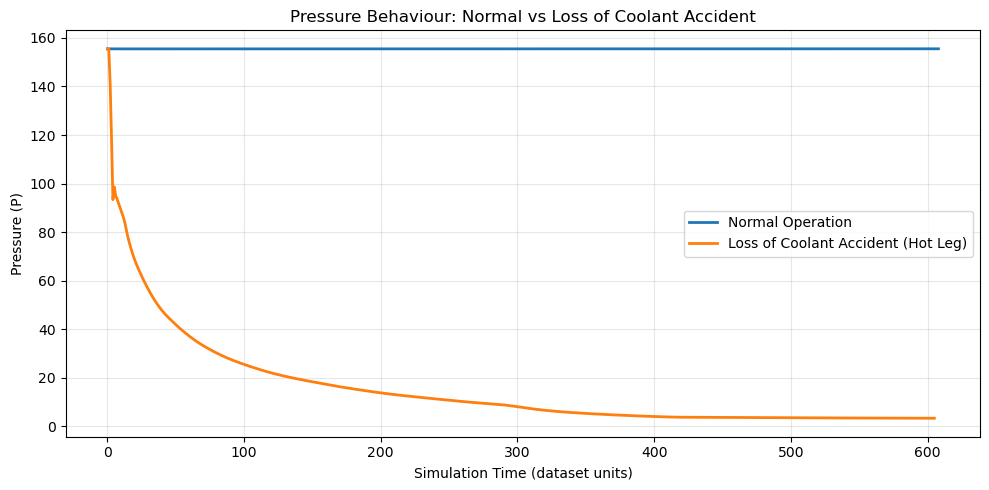

In [9]:

# Compare pressure measurements between two scenarios

normal_data = combined_df[
    combined_df["Scenario_ID"] == 0
]

fault_data = combined_df[
    combined_df["Scenario_ID"] == 1
]

plt.figure(figsize=(10, 5))

plt.plot(
    normal_data["TIME"],
    normal_data["P"],
    label="Normal Operation",
    linewidth=2
)

plt.plot(
    fault_data["TIME"],
    fault_data["P"],
    label="Loss of Coolant Accident (Hot Leg)",
    linewidth=2
)

plt.title("Pressure Behaviour: Normal vs Loss of Coolant Accident")
plt.xlabel("Simulation Time (dataset units)")
plt.ylabel("Pressure (P)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save the figure
plt.savefig(
    results_path / "pressure_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [10]:

# Compare the first 20 pressure readings

pressure_comparison = pd.DataFrame({
    "Time": normal_data["TIME"].iloc[:20].values,
    "Normal_Pressure": normal_data["P"].iloc[:20].values,
    "Fault_Pressure": fault_data["P"].iloc[:20].values
})

pressure_comparison["Pressure_Difference"] = (
    pressure_comparison["Normal_Pressure"] -
    pressure_comparison["Fault_Pressure"]
)

display(pressure_comparison.round(3))


,Time,Normal_Pressure,Fault_Pressure,Pressure_Difference
0,0,155.500,155.500,0.000
1,1,155.494,155.494,0.000
2,2,155.486,140.773,14.713
3,3,155.478,118.140,37.338
4,4,155.472,93.392,62.080
5,5,155.468,98.634,56.834
6,6,155.466,95.088,60.378
7,7,155.467,93.699,61.767
8,8,155.468,92.125,63.344
9,9,155.471,90.466,65.004


In [11]:

import numpy as np

# Identify sensor columns (exclude simulation time and labels)
sensor_columns = [
    col for col in normal_df.columns
    if col != "TIME"
]

# Compare the first 10 readings across all sensors
comparison_results = []

for i in range(10):
    normal_values = normal_data.iloc[i][sensor_columns].to_numpy(dtype=float)
    fault_values = fault_data.iloc[i][sensor_columns].to_numpy(dtype=float)

    # Count sensors with different values
    different_sensors = np.sum(
        ~np.isclose(normal_values, fault_values,
                    rtol=1e-5, atol=1e-8)
    )

    comparison_results.append({
        "Time": normal_data.iloc[i]["TIME"],
        "Different_Sensors": different_sensors,
        "Total_Sensors": len(sensor_columns)
    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df)


,Time,Different_Sensors,Total_Sensors
0,0,0,96
1,1,15,96
2,2,47,96
3,3,57,96
4,4,63,96
5,5,65,96
6,6,63,96
7,7,65,96
8,8,70,96
9,9,70,96


In [12]:

# Compare the first reading of every fault scenario
# against the first normal-operation reading

initial_comparison = []

normal_initial = normal_data.iloc[0][sensor_columns].to_numpy(dtype=float)

for scenario_id in sorted(combined_df["Scenario_ID"].unique()):

    if scenario_id == 0:
        continue

    scenario_data = combined_df[
        combined_df["Scenario_ID"] == scenario_id
    ]

    fault_initial = scenario_data.iloc[0][sensor_columns].to_numpy(dtype=float)

    different_sensors = np.sum(
        ~np.isclose(
            normal_initial,
            fault_initial,
            rtol=1e-5,
            atol=1e-8
        )
    )

    initial_comparison.append({
        "Scenario": scenario_data["Scenario"].iloc[0],
        "Different_Sensors_At_Time_0": different_sensors
    })

initial_df = pd.DataFrame(initial_comparison)

display(initial_df)


,Scenario,Different_Sensors_At_Time_0
0,01 - Loss of Coolant Accident (Hot Leg),0
1,02 - Loss of Coolant Accident (Cold Leg),0
2,03 - Steam Line Break Inside Containment,0
3,04 - Steam Line Break Outside Containment,0
4,05 - Spark Presence for Hydrogen Burn,0
5,06 - Loss of AC Power,0
6,07 - Loss of Flow (Locked Rotor),0
7,08 - Anticipated Transient without Scram,0
8,09 - Turbine Trip,0
9,10 - Steam Generator A Tube Rupture,0


In [13]:

# Create our modeling dataset
model_df = combined_df.copy()

# Exclude the common initial measurements from fault scenarios
model_df = model_df[
    ~(
        (model_df["Label"] == 1) &
        (model_df["TIME"] == 0)
    )
].copy()

# Reset row indices
model_df.reset_index(drop=True, inplace=True)

print("Original dataset:", combined_df.shape)
print("Modeling dataset:", model_df.shape)

print("\nUpdated class distribution:")
print(model_df["Label"].value_counts())

print("\nNumber of scenarios:", model_df["Scenario_ID"].nunique())

# Save the prepared dataset
prepared_path = project_path / "prepared_data"
prepared_path.mkdir(exist_ok=True)

model_df.to_csv(
    prepared_path / "npp_prepared.csv",
    index=False
)

print("\nPrepared dataset saved successfully!")


Original dataset: (12171, 100)
Modeling dataset: (12152, 100)

Updated class distribution:
Label
1    11543
0      609
Name: count, dtype: int64

Number of scenarios: 20

Prepared dataset saved successfully!
